# Семинар 1-СС. Есеп: IoU метрикасын есептеу

**Мақсаты:** объект детекциясында қолданылатын IoU (Intersection over Union) метрикасын есептейтін функция жазу және оны екі тіктөртбұрыш үшін тексеру.

## Есеп шарты

- $A = (50, 50, 150, 150)$ — болжам (predicted box)
- $B = (100, 100, 200, 200)$ — нақты (ground truth box)

Әр тіктөртбұрыш `(x1, y1, x2, y2)` форматында берілген (сол жоғарғы және оң төменгі бұрыштар).

$$IoU = \frac{\text{Қиылысу ауданы}}{\text{Бірігу ауданы}} = \frac{\text{Intersection}}{\text{Union}}$$

## IoU функциясы

In [1]:
def iou(a, b):  # (x1, y1, x2, y2)
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    area = lambda r: (r[2] - r[0]) * (r[3] - r[1])
    return inter / (area(a) + area(b) - inter)


A = (50, 50, 150, 150)   # болжам (predicted)
B = (100, 100, 200, 200)  # нақты (ground truth)

result = iou(A, B)
print(f"IoU(A, B) = {result:.4f}")


IoU(A, B) = 0.1429


## Есептеулерді қадам бойынша тексеру

Слайдтағы мәндермен салыстыру үшін қиылысу мен бірігу ауданын бөлек есептейміз.

In [2]:
def area(r):
    return (r[2] - r[0]) * (r[3] - r[1])

x1, y1 = max(A[0], B[0]), max(A[1], B[1])
x2, y2 = min(A[2], B[2]), min(A[3], B[3])
inter_area = max(0, x2 - x1) * max(0, y2 - y1)

union_area = area(A) + area(B) - inter_area

print(f"A ауданы: {area(A)}")
print(f"B ауданы: {area(B)}")
print(f"Қиылысу (Intersection): {inter_area}")
print(f"Бірігу (Union): {area(A)} + {area(B)} - {inter_area} = {union_area}")

threshold = 0.5
iou_value = inter_area / union_area
verdict = "TP (True Positive)" if iou_value >= threshold else "FP (False Positive)"
print(f"IoU = {inter_area} / {union_area} ≈ {iou_value:.4f}")
print(f"Шекара (threshold) = {threshold} -> {verdict} деп есептеледі"
      f" (себебі IoU {'>=' if iou_value >= threshold else '<'} {threshold})")


A ауданы: 10000
B ауданы: 10000
Қиылысу (Intersection): 2500
Бірігу (Union): 10000 + 10000 - 2500 = 17500
IoU = 2500 / 17500 ≈ 0.1429
Шекара (threshold) = 0.5 -> FP (False Positive) деп есептеледі (себебі IoU < 0.5)


## Визуализация



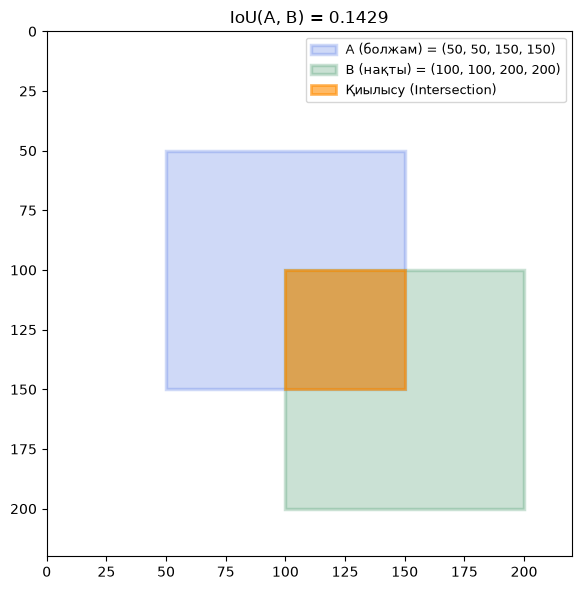

In [3]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(6, 6))

def draw_box(ax, box, color, label):
    x1, y1, x2, y2 = box
    rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                              linewidth=2.5, edgecolor=color,
                              facecolor=color, alpha=0.25, label=label)
    ax.add_patch(rect)

draw_box(ax, A, "royalblue", f"A (болжам) = {A}")
draw_box(ax, B, "seagreen", f"B (нақты) = {B}")

# Қиылысу аймағын бөлек ерекшелеу
ix1, iy1 = max(A[0], B[0]), max(A[1], B[1])
ix2, iy2 = min(A[2], B[2]), min(A[3], B[3])
if ix2 > ix1 and iy2 > iy1:
    inter_rect = patches.Rectangle((ix1, iy1), ix2 - ix1, iy2 - iy1,
                                    linewidth=2, edgecolor="darkorange",
                                    facecolor="darkorange", alpha=0.6,
                                    label="Қиылысу (Intersection)")
    ax.add_patch(inter_rect)

ax.set_xlim(0, 220)
ax.set_ylim(220, 0)  # Y осін кескін координаталары сияқты төмен қарай өсіру
ax.set_aspect("equal")
ax.set_title(f"IoU(A, B) = {iou(A, B):.4f}")
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.savefig("output/iou_visualization.png", bbox_inches="tight", dpi=120)
plt.show()


## Қорытынды

Берілген $A=(50,50,150,150)$ және $B=(100,100,200,200)$ тіктөртбұрыштары үшін қиылысу ауданы 2500, ал бірігу ауданы 17500-ге тең болғандықтан, IoU мәні шамамен 0.1428 құрайды. Бұл мән әдетте қолданылатын 0.5 шегінен төмен болғандықтан, мұндай детекция False Positive (FP) деп есептеледі, яғни болжам нақты объектімен жеткілікті дәрежеде сәйкес келмейді.